# Anexos — Notebook generador**Tesis:** *Modelos predictivos para identificar spam en correos electrónicos***Universidad de las Ciencias Informáticas — Facultad de Ciberseguridad****Autores:** Alejandro Vázquez Marrero · Jayson Ceballos Hernández---## DescripciónEste notebook genera los **Anexos** de la tesis a partir de los artefactos ya producidos por el notebook maestro (`results/metrics/`, `results/processed/`, `results/models/`, `results/vectors/`). **No re-entrena nada**: solo lee y formatea.## Anexos generados| Anexo | Contenido | Salida ||-------|-----------|--------|| **A** | Hiperparámetros óptimos por dataset y clasificador | PNG + CSV || **B** | Ejemplo concreto del flujo de preprocesamiento (EN y TR) | PNG + TXT || **C** | Verificación y reproducibilidad (versiones, hashes, semillas) | PNG + JSON || **D** | Vocabulario más discriminante (top TF-IDF por clase) | PNG por dataset || **E** | Distribución de longitudes pre/post preprocesamiento | PNG por dataset || **F** | Matriz de diversidad entre clasificadores base (Yule's Q) | PNG por dataset || **G** | Tiempos de entrenamiento por experimento | PNG + CSV || **H** | Comparativa F1-macro por representación | PNG por dataset |## Pre-requisitoHaber ejecutado el notebook maestro al menos una vez, de modo que existan:- `results/metrics/classifiers_results.csv`- `results/metrics/best_per_combo.json`- `results/metrics/hybrid_results.json`- `results/metrics/datasets_statistics.json`- `results/processed/*_raw.pkl` y `*_clean.pkl`- `results/processed/splits.pkl`- `results/models/*.joblib`## SalidaTodos los anexos se guardan en `results/figures/anexos/` dentro del proyecto en Drive.

# 1. Setup del entornoMontaje de Drive, importaciones y definición de paths.

In [1]:
# Montaje de Drive
import os
from pathlib import Path

try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print('[INFO] No estamos en Colab; ajusta PROJECT_ROOT manualmente.')

# === PATHS (mismos del notebook maestro) ===
PROJECT_ROOT = Path('/content/drive/MyDrive/spam_tesis')
DATA_DIR = PROJECT_ROOT / 'data'
MODELS_DIR = PROJECT_ROOT / 'models'

RESULTS_DIR = PROJECT_ROOT / 'results'
PROCESSED_DIR = RESULTS_DIR / 'processed'
VECTORS_DIR = RESULTS_DIR / 'vectors'
RESULTS_MODELS_DIR = RESULTS_DIR / 'models'
METRICS_DIR = RESULTS_DIR / 'metrics'
FIGURES_DIR = RESULTS_DIR / 'figures'
REPORT_DIR = RESULTS_DIR / 'report'

# Carpeta nueva para los anexos
ANEXOS_DIR = FIGURES_DIR / 'anexos'
ANEXOS_DIR.mkdir(parents=True, exist_ok=True)

print(f'[OK] PROJECT_ROOT : {PROJECT_ROOT}')
print(f'[OK] METRICS_DIR  : {METRICS_DIR}')
print(f'[OK] PROCESSED_DIR: {PROCESSED_DIR}')
print(f'[OK] ANEXOS_DIR   : {ANEXOS_DIR}')

Mounted at /content/drive
[OK] PROJECT_ROOT : /content/drive/MyDrive/spam_tesis
[OK] METRICS_DIR  : /content/drive/MyDrive/spam_tesis/results/metrics
[OK] PROCESSED_DIR: /content/drive/MyDrive/spam_tesis/results/processed
[OK] ANEXOS_DIR   : /content/drive/MyDrive/spam_tesis/results/figures/anexos


In [2]:
# Importaciones globales
import json
import pickle
import hashlib
import platform
import sys
import re
import string
import warnings
from datetime import datetime
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib

warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = 'DejaVu Sans'

print('[OK] Importaciones listas.')

[OK] Importaciones listas.


In [3]:
# === HELPER: guardar DataFrame como tabla PNG con estilo profesional ===
def save_table_png(df, title, output_path, subtitle=None, figsize=None,
                   col_widths=None, fontsize=10, header_color='#1F3864',
                   stripe_color='#E7EBF5', wrap_cols=None, max_col_width_chars=60):
    """
    Renderiza un DataFrame como una imagen PNG limpia y elegante.

    Args:
        df: DataFrame a renderizar.
        title: titulo principal.
        output_path: ruta del .png de salida.
        subtitle: subtitulo opcional.
        figsize: tupla (w, h) en pulgadas; si None, se calcula automaticamente.
        col_widths: lista de anchos relativos por columna; si None, equiprobables.
        fontsize: tamano de fuente del cuerpo.
        header_color: color de la cabecera.
        stripe_color: color de filas pares (zebra striping).
        wrap_cols: lista de nombres de columnas a las que aplicar wrapping de texto.
        max_col_width_chars: maximo de caracteres antes de hacer wrap.
    """
    df = df.copy()

    # Aplicar wrap si se solicita
    if wrap_cols:
        for col in wrap_cols:
            if col in df.columns:
                df[col] = df[col].astype(str).apply(
                    lambda s: '\n'.join(
                        [s[i:i+max_col_width_chars] for i in range(0, len(s), max_col_width_chars)]
                    ) if len(s) > max_col_width_chars else s
                )

    n_rows, n_cols = len(df), len(df.columns)

    # Auto figsize: ancho proporcional a columnas, alto a filas
    if figsize is None:
        # Ancho: estimar basado en contenido
        char_widths = []
        for col in df.columns:
            max_chars = max(
                len(str(col)),
                df[col].astype(str).str.len().max() if n_rows > 0 else len(str(col))
            )
            char_widths.append(max_chars)
        total_chars = sum(char_widths) + n_cols * 2
        fig_w = max(8, min(20, total_chars * 0.10))

        # Alto: contar lineas reales (por wraps con \n)
        max_lines_per_row = []
        for _, row in df.iterrows():
            max_lines = max([str(v).count('\n') + 1 for v in row.values])
            max_lines_per_row.append(max_lines)
        total_lines = sum(max_lines_per_row) if max_lines_per_row else 1
        fig_h = max(2.5, 1.2 + total_lines * 0.30 + (1 if subtitle else 0) * 0.3)

        figsize = (fig_w, fig_h)

    fig, ax = plt.subplots(figsize=figsize)
    ax.axis('off')

    # Titulo
    title_y = 0.98
    ax.set_title(title, fontsize=14, fontweight='bold', loc='center', pad=15, color='#1F3864')
    if subtitle:
        ax.text(0.5, 1.02, subtitle, transform=ax.transAxes, ha='center', va='bottom',
                fontsize=10, style='italic', color='#666666')

    # Anchos de columna
    if col_widths is None:
        col_widths = [1.0 / n_cols] * n_cols
    else:
        s = sum(col_widths)
        col_widths = [w / s for w in col_widths]

    table = ax.table(
        cellText=df.astype(str).values,
        colLabels=list(df.columns),
        cellLoc='center',
        loc='center',
        colWidths=col_widths
    )
    table.auto_set_font_size(False)
    table.set_fontsize(fontsize)
    table.scale(1, 1.6)

    # Estilo header
    for j in range(n_cols):
        cell = table[(0, j)]
        cell.set_facecolor(header_color)
        cell.set_text_props(weight='bold', color='white')
        cell.set_edgecolor('white')
        cell.set_linewidth(1.0)

    # Zebra striping y bordes en filas
    for i in range(1, n_rows + 1):
        for j in range(n_cols):
            cell = table[(i, j)]
            if i % 2 == 0:
                cell.set_facecolor(stripe_color)
            else:
                cell.set_facecolor('white')
            cell.set_edgecolor('#CCCCCC')
            cell.set_linewidth(0.5)
            cell.set_text_props(color='#222222')

    plt.savefig(output_path, dpi=200, bbox_inches='tight', facecolor='white', pad_inches=0.3)
    plt.close()
    return output_path


print('[OK] Helper save_table_png definido.')

[OK] Helper save_table_png definido.


In [4]:
# === CHEQUEOS PREVIOS: que existan los artefactos del maestro ===
required = {
    'classifiers_results.csv': METRICS_DIR / 'classifiers_results.csv',
    'best_per_combo.json'   : METRICS_DIR / 'best_per_combo.json',
    'hybrid_results.json'   : METRICS_DIR / 'hybrid_results.json',
    'datasets_statistics.json': METRICS_DIR / 'datasets_statistics.json',
    'splits.pkl'            : PROCESSED_DIR / 'splits.pkl',
    'datasets_config.pkl'   : PROCESSED_DIR / 'datasets_config.pkl',
}

missing = []
for name, p in required.items():
    if not p.exists():
        missing.append(name)
        print(f'  [FALTA] {name}: {p}')
    else:
        size_kb = p.stat().st_size / 1024
        print(f'  [OK]    {name:<28} ({size_kb:>8.1f} KB)')

if missing:
    raise FileNotFoundError(
        f'Faltan {len(missing)} artefactos. Ejecuta primero el notebook maestro.'
    )

print('\n[OK] Todos los artefactos requeridos estan presentes.')

  [OK]    classifiers_results.csv      (     6.7 KB)
  [OK]    best_per_combo.json          (     3.2 KB)
  [OK]    hybrid_results.json          (     7.2 KB)
  [OK]    datasets_statistics.json     (     1.3 KB)
  [OK]    splits.pkl                   (  6687.3 KB)
  [OK]    datasets_config.pkl          (     0.5 KB)

[OK] Todos los artefactos requeridos estan presentes.


# Anexo A — Hiperparámetros óptimos por datasetPara cada combinación (dataset, clasificador) se reporta la **mejor representación vectorial** según F1-macro en validación cruzada, junto con los hiperparámetros óptimos hallados por `GridSearchCV`. Esta tabla complementa la tabla resumen del Capítulo III mostrando, en un solo lugar, **todas** las configuraciones efectivamente seleccionadas para construir los modelos finales.

In [5]:
# === CARGA DE DATOS ===
df_clf = pd.read_csv(METRICS_DIR / 'classifiers_results.csv')
with open(METRICS_DIR / 'best_per_combo.json', 'r', encoding='utf-8') as f:
    best_per_combo = json.load(f)

# Etiquetas legibles
CLF_LABELS = {
    'naive_bayes': 'Naive Bayes',
    'svm_rbf': 'SVM (RBF)',
    'random_forest': 'Random Forest',
}
REPR_LABELS = {
    'bow': 'BoW',
    'tfidf': 'TF-IDF',
    'emb': 'Embeddings',
    'bow_svd': 'BoW + SVD',
    'tfidf_svd': 'TF-IDF + SVD',
    'emb_pca': 'Embeddings + PCA',
    'scaled': 'StandardScaler',
    'pca': 'StandardScaler + PCA',
}

# === CONSTRUIR TABLA ===
rows = []
for ds in sorted(set(df_clf['dataset'])):
    for clf in ['naive_bayes', 'svm_rbf', 'random_forest']:
        key = f'{ds}__{clf}'
        if key not in best_per_combo:
            continue
        info = best_per_combo[key]
        # Limpiar params: convertir string a dict
        try:
            params = eval(info['best_params']) if isinstance(info['best_params'], str) else info['best_params']
            params_str = ', '.join([f"{k}={v}" for k, v in params.items()])
        except Exception:
            params_str = str(info['best_params'])
        rows.append({
            'Dataset': ds,
            'Clasificador': CLF_LABELS.get(clf, clf),
            'Mejor representacion': REPR_LABELS.get(info['representation'], info['representation']),
            'Hiperparametros optimos': params_str,
            'F1-macro CV': f"{info['cv_f1_macro']:.4f}",
            'F1-macro Test': f"{info['test_f1_macro']:.4f}",
        })

df_anexo_a = pd.DataFrame(rows)
print(f'Total filas: {len(df_anexo_a)}')
print(df_anexo_a.to_string(index=False))

Total filas: 14
        Dataset  Clasificador Mejor representacion             Hiperparametros optimos F1-macro CV F1-macro Test
       sms_spam   Naive Bayes               TF-IDF                          alpha=0.01      0.9821        0.9191
       sms_spam     SVM (RBF)           Embeddings                  C=100, gamma=scale      0.9951        0.9437
       sms_spam Random Forest               TF-IDF max_depth=None, min_samples_split=2      0.9905        0.9517
 spam_ham_email   Naive Bayes                  BoW                          alpha=0.01      0.9011        0.9703
 spam_ham_email     SVM (RBF)               TF-IDF                   C=10, gamma=scale      0.9929        0.9808
 spam_ham_email Random Forest         TF-IDF + SVD max_depth=None, min_samples_split=2      0.9837        0.9737
       spambase     SVM (RBF)       StandardScaler                   C=10, gamma=scale      0.9442        0.9177
       spambase Random Forest       StandardScaler max_depth=None, min_samples_s

In [ ]:
# === GUARDAR PNG Y CSV ===
out_csv = ANEXOS_DIR / 'anexo_A_hiperparametros.csv'
out_png = ANEXOS_DIR / 'anexo_A_hiperparametros.png'

df_anexo_a.to_csv(out_csv, index=False)

save_table_png(
    df_anexo_a,
    title='Anexo A. Hiperparametros optimos por dataset y clasificador',
    subtitle='Mejor representacion vectorial y configuracion seleccionada por GridSearchCV (F1-macro, 5-fold CV)',
    output_path=out_png,
    col_widths=[1.6, 1.4, 1.5, 3.5, 1.0, 1.0],
    fontsize=9,
    wrap_cols=['Hiperparametros optimos'],
    max_col_width_chars=45,
)

print(f'[OK] Guardado: {out_csv}')
print(f'[OK] Guardado: {out_png}')

[OK] Guardado: /content/drive/MyDrive/spam_tesis/results/figures/anexos/anexo_A_hiperparametros.csv
[OK] Guardado: /content/drive/MyDrive/spam_tesis/results/figures/anexos/anexo_A_hiperparametros.png


# Anexo B — Ejemplo concreto del flujo de preprocesamientoPara ilustrar de forma reproducible el efecto de la tubería de preprocesamiento descrita en el epígrafe **II.4**, se muestra paso a paso la transformación de un mensaje real de cada idioma (inglés y turco). Cada fila representa el estado del texto tras aplicar una operación atómica de la tubería.Las operaciones siguen el orden:1. Texto original (sin modificar).2. Conversión a minúsculas.3. Eliminación de etiquetas HTML.4. Sustitución de URLs por `<URL>`.5. Sustitución de correos por `<EMAIL>`.6. Eliminación de dígitos.7. Eliminación de signos de puntuación.8. Tokenización.9. Eliminación de *stopwords*.10. Lematización.11. Filtrado por longitud mínima (`MIN_TOKEN_LENGTH = 3`).12. Texto final reconstruido.

In [ ]:
# === SETUP DE PIPELINES (replica II.4) ===
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords as nltk_stopwords

# Cargar configs y datasets
with open(PROCESSED_DIR / 'datasets_config.pkl', 'rb') as f:
    DATASETS_CONFIG = pickle.load(f)

datasets_raw = {}
for name in DATASETS_CONFIG.keys():
    p = PROCESSED_DIR / f'{name}_raw.pkl'
    if p.exists():
        datasets_raw[name] = pd.read_pickle(p)

stopwords_en = set(nltk_stopwords.words('english'))
stopwords_tr = set(nltk_stopwords.words('turkish'))
SPECIAL_TOKENS = {'<URL>', '<EMAIL>'}
MIN_TOKEN_LENGTH = 3

# Cargar spaCy y zeyrek (ya deberian estar instalados por el maestro)
import spacy
try:
    nlp_en = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
except OSError:
    !python -m spacy download en_core_web_sm --quiet
    nlp_en = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

try:
    import zeyrek
    lemmatizer_tr = zeyrek.MorphAnalyzer()
except ImportError:
    !pip install -q zeyrek==0.1.3
    import zeyrek
    lemmatizer_tr = zeyrek.MorphAnalyzer()

print('[OK] Pipelines listos.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 931.0/931.0 kB 11.2 MB/s eta 0:00:00
[OK] Pipelines listos.


In [ ]:
# === FUNCION: preprocesamiento paso a paso ===
def trace_preprocess_en(text):
    """Devuelve una lista [(paso, descripcion, resultado), ...]"""
    trace = []
    trace.append(('1', 'Texto original', text))

    s = text.lower()
    trace.append(('2', 'Minusculas', s))

    s = re.sub(r'<[^>]+>', ' ', s)
    trace.append(('3', 'Eliminar HTML', s))

    s = re.sub(r'http[s]?://\S+|www\.\S+', ' <URL> ', s)
    trace.append(('4', 'Sustituir URLs', s))

    s = re.sub(r'\S+@\S+\.\S+', ' <EMAIL> ', s)
    trace.append(('5', 'Sustituir correos', s))

    s = re.sub(r'\d+', ' ', s)
    trace.append(('6', 'Eliminar digitos', s))

    s = s.translate(str.maketrans('', '', string.punctuation))
    s = re.sub(r'\s+', ' ', s).strip()
    trace.append(('7', 'Eliminar puntuacion', s))

    # spaCy
    doc = nlp_en(s)
    raw_tokens = [t.text for t in doc if not t.is_space]
    trace.append(('8', 'Tokenizacion (spaCy)', ' | '.join(raw_tokens)))

    # Sin stopwords
    no_stop = [t.text for t in doc if t.text in SPECIAL_TOKENS or
               (not t.is_punct and not t.is_space and t.lemma_ not in stopwords_en)]
    trace.append(('9', 'Sin stopwords', ' | '.join(no_stop)))

    # Lematizacion
    lemmas = []
    for t in doc:
        if t.text in SPECIAL_TOKENS:
            lemmas.append(t.text)
        elif t.is_punct or t.is_space:
            continue
        elif t.lemma_ in stopwords_en:
            continue
        else:
            lemmas.append(t.lemma_)
    trace.append(('10', 'Lematizacion', ' | '.join(lemmas)))

    # Filtrado por longitud
    final = [tk for tk in lemmas if tk in SPECIAL_TOKENS or len(tk) >= MIN_TOKEN_LENGTH]
    trace.append(('11', f'Long. minima >={MIN_TOKEN_LENGTH}', ' | '.join(final)))

    final_text = ' '.join(final)
    trace.append(('12', 'Texto final', final_text))

    return trace


def trace_preprocess_tr(text):
    trace = []
    trace.append(('1', 'Texto original', text))

    s = text.lower()
    trace.append(('2', 'Minusculas', s))

    s = re.sub(r'<[^>]+>', ' ', s)
    trace.append(('3', 'Eliminar HTML', s))

    s = re.sub(r'http[s]?://\S+|www\.\S+', ' <URL> ', s)
    trace.append(('4', 'Sustituir URLs', s))

    s = re.sub(r'\S+@\S+\.\S+', ' <EMAIL> ', s)
    trace.append(('5', 'Sustituir correos', s))

    s = re.sub(r'\d+', ' ', s)
    trace.append(('6', 'Eliminar digitos', s))

    s = re.sub(r'[^\w\sçğıöşüÇĞİÖŞÜ<>]', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    trace.append(('7', 'Eliminar puntuacion (preserva diacriticos TR)', s))

    raw_tokens = s.split()
    trace.append(('8', 'Tokenizacion (split)', ' | '.join(raw_tokens)))

    no_stop = [t for t in raw_tokens if t in SPECIAL_TOKENS or t not in stopwords_tr]
    trace.append(('9', 'Sin stopwords', ' | '.join(no_stop)))

    lemmas = []
    for tok in no_stop:
        if tok in SPECIAL_TOKENS:
            lemmas.append(tok)
            continue
        try:
            analyses = lemmatizer_tr.lemmatize(tok)
            if analyses and len(analyses[0]) > 1 and analyses[0][1]:
                lemmas.append(analyses[0][1][0].lower())
            else:
                lemmas.append(tok)
        except Exception:
            lemmas.append(tok)
    trace.append(('10', 'Lematizacion (Zeyrek)', ' | '.join(lemmas)))

    final = [tk for tk in lemmas if tk in SPECIAL_TOKENS or len(tk) >= MIN_TOKEN_LENGTH]
    trace.append(('11', f'Long. minima >={MIN_TOKEN_LENGTH}', ' | '.join(final)))

    final_text = ' '.join(final)
    trace.append(('12', 'Texto final', final_text))

    return trace


print('[OK] Funciones trace definidas.')

[OK] Funciones trace definidas.


In [ ]:
# === SELECCIONAR EJEMPLOS REPRESENTATIVOS ===
# 1) un spam en ingles del sms_spam (clasico)
# 2) un spam en turco del trspam

# Ejemplo EN: buscar uno con URL y/o digitos para que sea ilustrativo
def find_example(df, want_label=1, prefer_patterns=None, min_len=80, max_len=350):
    if prefer_patterns is None:
        prefer_patterns = [r'http', r'www', r'\d+', r'@']
    candidates = df[df['label'] == want_label].copy()
    candidates = candidates[
        candidates['text'].str.len().between(min_len, max_len)
    ]
    # Priorizar los que matcheen patrones interesantes
    for pat in prefer_patterns:
        m = candidates[candidates['text'].str.contains(pat, case=False, regex=True, na=False)]
        if len(m) > 0:
            return m.iloc[0]['text']
    if len(candidates) > 0:
        return candidates.iloc[0]['text']
    return df[df['label'] == want_label].iloc[0]['text']


# === EN ===
en_dataset_choice = None
for cand in ['sms_spam', 'spam_ham_email', 'youtube_shakira']:
    if cand in datasets_raw:
        en_dataset_choice = cand
        break

if en_dataset_choice:
    example_en = find_example(datasets_raw[en_dataset_choice], want_label=1)
    print(f'EJEMPLO EN ({en_dataset_choice}):')
    print(example_en)
else:
    example_en = None

# === TR ===
if 'trspam' in datasets_raw:
    example_tr = find_example(datasets_raw['trspam'], want_label=1, min_len=40, max_len=300)
    print(f'\nEJEMPLO TR (trspam):')
    print(example_tr)
else:
    example_tr = None

EJEMPLO EN (sms_spam):
XXXMobileMovieClub: To use your credit, click the WAP link in the next txt message or click here>> http://wap. xxxmobilemovieclub.com?n=QJKGIGHJJGCBL

EJEMPLO TR (trspam):
Yöneticiniz tarafından belirlenen gibi Posta Kutusu O Depolama Sınırı
Aşıldı Has, Ve Sen Bu Re-Validate kadar Yeni postaları almak için mümkün
olmayacaktır. Için yeniden Validate => Tıklayınız
<https://docs.google.com/spreadsheet/viewform?formkey=dE51NjE0RXRHaDFQTERJbDJzanRXbEE6MQ#gid=0>


In [ ]:
# === EJECUTAR TRACE Y GUARDAR ===
def trace_to_df(trace, max_chars=110):
    rows = []
    for paso, desc, out in trace:
        s = str(out)
        if len(s) > max_chars:
            s = s[:max_chars - 3] + '...'
        rows.append({'Paso': paso, 'Operacion': desc, 'Resultado': s})
    return pd.DataFrame(rows)


# Anexo B.1 — EN
if example_en is not None:
    trace_en = trace_preprocess_en(example_en)
    df_b_en = trace_to_df(trace_en, max_chars=120)
    print('=== Trace EN ===')
    print(df_b_en.to_string(index=False))

    out_png_en = ANEXOS_DIR / 'anexo_B_preprocesamiento_EN.png'
    save_table_png(
        df_b_en,
        title='Anexo B.1. Flujo de preprocesamiento - ejemplo en ingles',
        subtitle=f'Mensaje de spam tomado del dataset "{en_dataset_choice}"',
        output_path=out_png_en,
        col_widths=[0.4, 2.0, 6.0],
        fontsize=9,
        wrap_cols=['Resultado'],
        max_col_width_chars=70,
    )

    # Guardar tambien en TXT para auditoria
    with open(ANEXOS_DIR / 'anexo_B_preprocesamiento_EN.txt', 'w', encoding='utf-8') as f:
        f.write(f'Anexo B.1 - Flujo de preprocesamiento (EN)\n')
        f.write(f'Dataset: {en_dataset_choice}\n')
        f.write('=' * 90 + '\n')
        for paso, desc, out in trace_en:
            f.write(f'[{paso}] {desc}\n')
            f.write(f'    {out}\n\n')
    print(f'[OK] Guardado: {out_png_en}')

# Anexo B.2 — TR
if example_tr is not None:
    trace_tr = trace_preprocess_tr(example_tr)
    df_b_tr = trace_to_df(trace_tr, max_chars=120)
    print('\n=== Trace TR ===')
    print(df_b_tr.to_string(index=False))

    out_png_tr = ANEXOS_DIR / 'anexo_B_preprocesamiento_TR.png'
    save_table_png(
        df_b_tr,
        title='Anexo B.2. Flujo de preprocesamiento - ejemplo en turco',
        subtitle='Mensaje de spam tomado del dataset "trspam"',
        output_path=out_png_tr,
        col_widths=[0.4, 2.0, 6.0],
        fontsize=9,
        wrap_cols=['Resultado'],
        max_col_width_chars=70,
    )

    with open(ANEXOS_DIR / 'anexo_B_preprocesamiento_TR.txt', 'w', encoding='utf-8') as f:
        f.write(f'Anexo B.2 - Flujo de preprocesamiento (TR)\n')
        f.write('=' * 90 + '\n')
        for paso, desc, out in trace_tr:
            f.write(f'[{paso}] {desc}\n')
            f.write(f'    {out}\n\n')
    print(f'[OK] Guardado: {out_png_tr}')

=== Trace EN ===
Paso            Operacion                                                                                                                Resultado
   1       Texto original XXXMobileMovieClub: To use your credit, click the WAP link in the next txt message or click here>> http://wap. xxxmob...
   2           Minusculas xxxmobilemovieclub: to use your credit, click the wap link in the next txt message or click here>> http://wap. xxxmob...
   3        Eliminar HTML xxxmobilemovieclub: to use your credit, click the wap link in the next txt message or click here>> http://wap. xxxmob...
   4       Sustituir URLs xxxmobilemovieclub: to use your credit, click the wap link in the next txt message or click here>>  <URL>  xxxmobilem...
   5    Sustituir correos xxxmobilemovieclub: to use your credit, click the wap link in the next txt message or click here>>  <URL>  xxxmobilem...
   6     Eliminar digitos xxxmobilemovieclub: to use your credit, click the wap link in the next txt 

# Anexo C — Verificación y reproducibilidadEste anexo documenta la información necesaria para que cualquier investigador pueda **reproducir bit-a-bit** los resultados reportados en la tesis. Incluye:- Versiones exactas de **Python** y de las bibliotecas científicas utilizadas.- **Semilla aleatoria** fija (`RANDOM_STATE = 42`) usada en `train_test_split`, `GridSearchCV`, `StratifiedKFold`, `SMOTE`, `TruncatedSVD`, `PCA`, los clasificadores y la regresión logística meta.- **Hashes SHA-256** de los principales artefactos generados por el pipeline (CSV de métricas, JSON de resultados, modelos `.joblib`, embeddings cacheados).- **Configuración global**: tamaño de partición, número de folds, n-grams, cortes de frecuencia, dimensiones de reducción.- **Información del entorno de ejecución** (sistema operativo, hardware).

In [ ]:
# === RECOLECCION DE INFO DE REPRODUCIBILIDAD ===

# 1) VERSIONES
def get_version(pkg_name, import_name=None):
    if import_name is None:
        import_name = pkg_name
    try:
        mod = __import__(import_name)
        return mod.__version__ if hasattr(mod, '__version__') else 'N/A'
    except Exception:
        return 'no instalado'

versions = {
    'Python'       : sys.version.split()[0],
    'NumPy'        : get_version('numpy'),
    'Pandas'       : get_version('pandas'),
    'SciPy'        : get_version('scipy'),
    'scikit-learn' : get_version('sklearn'),
    'imbalanced-learn': get_version('imbalanced-learn', 'imblearn'),
    'matplotlib'   : get_version('matplotlib'),
    'seaborn'      : get_version('seaborn'),
    'spaCy'        : get_version('spacy'),
    'NLTK'         : get_version('nltk'),
    'gensim'       : get_version('gensim'),
    'zeyrek'       : get_version('zeyrek'),
    'joblib'       : get_version('joblib'),
}

print('=== Versiones ===')
for k, v in versions.items():
    print(f'  {k:<20} {v}')

=== Versiones ===
  Python               3.12.13
  NumPy                2.0.2
  Pandas               2.2.2
  SciPy                1.16.3
  scikit-learn         1.6.1
  imbalanced-learn     0.14.1
  matplotlib           3.10.0
  seaborn              0.13.2
  spaCy                3.8.14
  NLTK                 3.9.1
  gensim               no instalado
  zeyrek               0.1.2
  joblib               1.5.3


In [ ]:
# 2) ENTORNO
env_info = {
    'Sistema operativo': f'{platform.system()} {platform.release()}',
    'Maquina'          : platform.machine(),
    'Procesador'       : platform.processor() or 'N/A',
    'Python ejecutable': sys.executable,
    'Fecha de generacion del anexo': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
}

# CPU/RAM si estamos en Linux/Colab
try:
    import psutil
    env_info['CPUs logicos'] = str(psutil.cpu_count())
    env_info['RAM (GB)']     = f"{psutil.virtual_memory().total / (1024**3):.1f}"
except ImportError:
    pass

print('=== Entorno ===')
for k, v in env_info.items():
    print(f'  {k:<35} {v}')

=== Entorno ===
  Sistema operativo                   Linux 6.6.122+
  Maquina                             x86_64
  Procesador                          x86_64
  Python ejecutable                   /usr/bin/python3
  Fecha de generacion del anexo       2026-05-09 21:28:18
  CPUs logicos                        2
  RAM (GB)                            12.7


In [ ]:
# 3) HASHES SHA-256 de artefactos clave
def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        while True:
            data = f.read(chunk_size)
            if not data:
                break
            h.update(data)
    return h.hexdigest()

# Artefactos a hashear
hash_targets = []

# Metricas y reportes
for p in sorted(METRICS_DIR.glob('*.csv')):
    hash_targets.append(p)
for p in sorted(METRICS_DIR.glob('*.json')):
    hash_targets.append(p)
for p in sorted(REPORT_DIR.glob('*.json')):
    hash_targets.append(p)
for p in sorted(REPORT_DIR.glob('*.csv')):
    hash_targets.append(p)

# Modelos
for p in sorted(RESULTS_MODELS_DIR.glob('*.joblib')):
    hash_targets.append(p)

# Splits y configs
for p in [PROCESSED_DIR / 'splits.pkl', PROCESSED_DIR / 'datasets_config.pkl']:
    if p.exists():
        hash_targets.append(p)

# Datasets crudos (originales)
for p in sorted(DATA_DIR.iterdir()):
    if p.is_file() and p.suffix in ['.csv', '.data']:
        hash_targets.append(p)

# Computar
print(f'Computando hashes de {len(hash_targets)} archivos...')
hash_rows = []
for p in hash_targets:
    try:
        h = sha256_file(p)
        size_kb = p.stat().st_size / 1024
        rel = str(p.relative_to(PROJECT_ROOT))
        hash_rows.append({
            'Archivo': rel,
            'Tamano (KB)': f'{size_kb:,.1f}',
            'SHA-256 (primeros 16 caracteres)': h[:16] + '...',
            'SHA-256 completo': h,
        })
    except Exception as e:
        print(f'  [WARN] {p.name}: {e}')

df_hashes = pd.DataFrame(hash_rows)
print(f'[OK] Hasheados {len(df_hashes)} archivos.')

Computando hashes de 90 archivos...


In [ ]:
# 4) CONSTRUIR TABLA DE CONFIGURACION Y SEMILLAS
config_rows = [
    ('Semilla aleatoria global (RANDOM_STATE)', '42'),
    ('Tamano de la particion test (TEST_SIZE)', '0.20'),
    ('Particion estratificada', 'Si (sklearn.train_test_split, stratify=y)'),
    ('K-folds en CV anidada (GRID_CV_FOLDS)', '5'),
    ('K-folds en evaluacion final (CV_FOLDS)', '5'),
    ('Metrica de scoring en GridSearchCV', 'f1_macro'),
    ('Longitud minima de token (MIN_TOKEN_LENGTH)', '3'),
    ('Rango de n-gramas (NGRAM_RANGE)', '(1, 2)'),
    ('Maximo de features BoW/TF-IDF (MAX_FEATURES)', '10000'),
    ('Frecuencia minima documento (MIN_DF)', '2'),
    ('Frecuencia maxima documento (MAX_DF)', '0.95'),
    ('Dimension de embeddings (EMBEDDING_DIM)', '300'),
    ('Componentes Truncated SVD (SVD_N_COMPONENTS)', '300'),
    ('Componentes PCA embeddings (PCA_N_COMPONENTS)', '100'),
    ('Componentes PCA Spambase (PCA_SPAMBASE)', '30'),
    ('Vecinos SMOTE (SMOTE_K)', '5'),
    ('Nivel de significacion (ALPHA_SIGNIFICANCE)', '0.05'),
    ('Modelo Word2Vec', 'GoogleNews-vectors-negative300.bin'),
    ('Modelo FastText TR', 'cc.tr.300.vec'),
    ('Lematizador EN', 'spaCy en_core_web_sm'),
    ('Lematizador TR', 'Zeyrek MorphAnalyzer'),
    ('Meta-clasificador del stacking', 'LogisticRegression (max_iter=1000, class_weight=balanced)'),
]
df_config = pd.DataFrame(config_rows, columns=['Parametro', 'Valor'])

# === GUARDAR ANEXO C ===

# C.1 - Versiones
df_versions = pd.DataFrame([{'Componente': k, 'Version': v} for k, v in versions.items()])
save_table_png(
    df_versions,
    title='Anexo C.1. Versiones de software utilizadas',
    subtitle='Snapshot del entorno de ejecucion en el momento de generar la tesis',
    output_path=ANEXOS_DIR / 'anexo_C1_versiones.png',
    col_widths=[1.5, 1.0],
    fontsize=10,
)

# C.2 - Configuracion experimental
save_table_png(
    df_config,
    title='Anexo C.2. Configuracion experimental y semillas aleatorias',
    subtitle='Constantes globales del Capitulo II que definen exactamente el experimento',
    output_path=ANEXOS_DIR / 'anexo_C2_configuracion.png',
    col_widths=[2.5, 2.5],
    fontsize=10,
    wrap_cols=['Valor'],
    max_col_width_chars=55,
)

# C.3 - Entorno
df_env = pd.DataFrame([{'Atributo': k, 'Valor': str(v)} for k, v in env_info.items()])
save_table_png(
    df_env,
    title='Anexo C.3. Entorno de ejecucion',
    output_path=ANEXOS_DIR / 'anexo_C3_entorno.png',
    col_widths=[2.0, 3.0],
    fontsize=10,
)

# C.4 - Hashes (PNG con vista corta)
df_hashes_short = df_hashes[['Archivo', 'Tamano (KB)', 'SHA-256 (primeros 16 caracteres)']].copy()
save_table_png(
    df_hashes_short,
    title='Anexo C.4. Hashes SHA-256 de los artefactos generados',
    subtitle='Permite verificar integridad bit-a-bit de los archivos del experimento (versiones completas en CSV adjunto)',
    output_path=ANEXOS_DIR / 'anexo_C4_hashes.png',
    col_widths=[3.5, 1.0, 1.8],
    fontsize=8,
)

# Guardar version completa de hashes en CSV
df_hashes.to_csv(ANEXOS_DIR / 'anexo_C4_hashes_completo.csv', index=False)

# JSON consolidado de reproducibilidad
repro_dict = {
    'metadata': {
        'fecha_generacion': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'random_state': 42,
    },
    'versiones': versions,
    'entorno': env_info,
    'configuracion_experimental': dict(config_rows),
    'hashes_sha256': {row['Archivo']: row['SHA-256 completo'] for row in hash_rows},
}
with open(ANEXOS_DIR / 'anexo_C_reproducibilidad.json', 'w', encoding='utf-8') as f:
    json.dump(repro_dict, f, indent=2, ensure_ascii=False)

print('[OK] Anexos C.1, C.2, C.3, C.4 generados.')
print(f'[OK] anexo_C_reproducibilidad.json guardado.')

# Anexo D — Vocabulario más discriminante (top TF-IDF por clase)Para cada dataset textual se reportan los **20 términos (1-gramas y 2-gramas) con mayor peso TF-IDF promedio** en la clase spam y los 20 con mayor peso en la clase ham, calculados sobre el conjunto de entrenamiento. Esta tabla aporta interpretabilidad cualitativa al modelo y permite verificar que los términos prominentes coinciden con la intuición de cada dominio (URLs, llamadas a la acción, ofertas, etc.).> **Nota metodológica:** se recalcula el `TfidfVectorizer` con los mismos hiperparámetros del Capítulo II (`ngram_range=(1,2)`, `max_features=10000`, `min_df=2`, `max_df=0.95`, `sublinear_tf=True`) sobre el split de entrenamiento, garantizando consistencia con los modelos entrenados.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Cargar splits y datasets limpios
with open(PROCESSED_DIR / 'splits.pkl', 'rb') as f:
    splits = pickle.load(f)

NGRAM_RANGE = (1, 2)
MAX_FEATURES = 10000
MIN_DF = 2
MAX_DF = 0.95
TOP_N = 20

textual_datasets = [
    name for name, cfg in DATASETS_CONFIG.items()
    if cfg.get('format') == 'text'
]

print(f'Datasets textuales: {textual_datasets}')

In [ ]:
# === CALCULAR TOP TF-IDF POR CLASE ===
def top_tfidf_per_class(X_train_text, y_train, top_n=20):
    """Devuelve dos listas (spam_top, ham_top) con [(termino, score_promedio)]."""
    tv = TfidfVectorizer(
        ngram_range=NGRAM_RANGE, max_features=MAX_FEATURES,
        min_df=MIN_DF, max_df=MAX_DF, sublinear_tf=True, lowercase=False
    )
    X = tv.fit_transform(X_train_text)
    feature_names = np.array(tv.get_feature_names_out())

    y = np.asarray(y_train)
    spam_mean = np.asarray(X[y == 1].mean(axis=0)).ravel()
    ham_mean  = np.asarray(X[y == 0].mean(axis=0)).ravel()

    # Top spam: terminos con mayor TF-IDF promedio en spam Y bajo en ham
    spam_score = spam_mean - ham_mean
    ham_score  = ham_mean - spam_mean

    top_spam_idx = np.argsort(spam_score)[::-1][:top_n]
    top_ham_idx  = np.argsort(ham_score)[::-1][:top_n]

    spam_list = [(feature_names[i], spam_mean[i]) for i in top_spam_idx]
    ham_list  = [(feature_names[i], ham_mean[i]) for i in top_ham_idx]
    return spam_list, ham_list


for ds_name in textual_datasets:
    if ds_name not in splits:
        continue
    print(f'\n=== {ds_name} ===')
    X_train = splits[ds_name]['X_train']
    y_train = splits[ds_name]['y_train']

    spam_top, ham_top = top_tfidf_per_class(X_train, y_train, top_n=TOP_N)

    rows = []
    for i in range(TOP_N):
        s_term, s_val = spam_top[i] if i < len(spam_top) else ('', 0.0)
        h_term, h_val = ham_top[i] if i < len(ham_top) else ('', 0.0)
        rows.append({
            '#': i + 1,
            'Top spam (termino)': s_term,
            'TF-IDF spam': f'{s_val:.4f}',
            'Top ham (termino)': h_term,
            'TF-IDF ham': f'{h_val:.4f}',
        })
    df_top = pd.DataFrame(rows)
    print(df_top.head(10).to_string(index=False))

    out_png = ANEXOS_DIR / f'anexo_D_top_tfidf_{ds_name}.png'
    save_table_png(
        df_top,
        title=f'Anexo D. Top {TOP_N} terminos discriminantes - {ds_name}',
        subtitle='Diferencia de TF-IDF promedio entre clases (spam vs ham) sobre el conjunto de entrenamiento',
        output_path=out_png,
        col_widths=[0.3, 1.5, 0.8, 1.5, 0.8],
        fontsize=9,
    )
    df_top.to_csv(ANEXOS_DIR / f'anexo_D_top_tfidf_{ds_name}.csv', index=False)
    print(f'[OK] Guardado: {out_png.name}')

# Anexo E — Distribución de longitudes pre/post preprocesamientoSe compara la longitud (en caracteres y en tokens) de los mensajes **antes** y **después** de aplicar la tubería de preprocesamiento, separando por clase. Esto cuantifica el efecto del preprocesamiento (eliminación de *stopwords*, lematización, filtros) sobre el corpus y evidencia que la reducción de ruido no destruye información semántica relevante (las distribuciones siguen siendo separables entre clases).

In [ ]:
# === CARGAR RAW Y CLEAN ===
datasets_clean = {}
for name in DATASETS_CONFIG.keys():
    p = PROCESSED_DIR / f'{name}_clean.pkl'
    if p.exists():
        datasets_clean[name] = pd.read_pickle(p)

print(f'Raw  : {list(datasets_raw.keys())}')
print(f'Clean: {list(datasets_clean.keys())}')

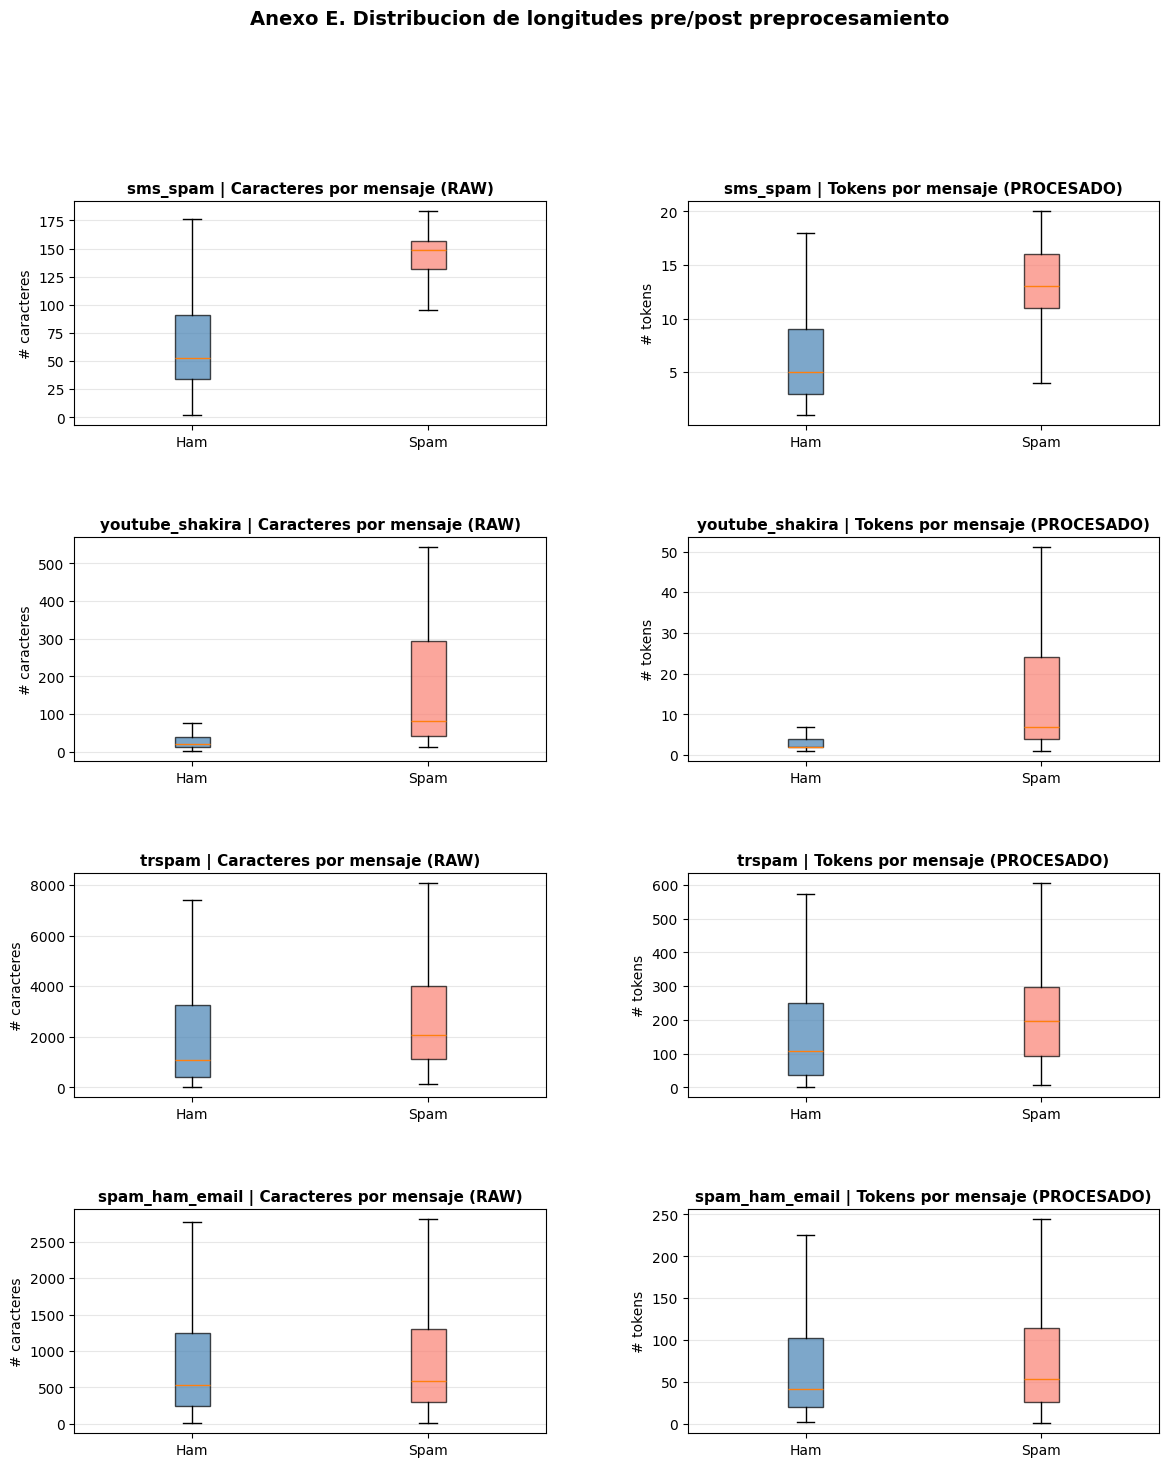

[OK] anexo_E_longitudes_distribucion.png


In [ ]:
# === FIGURA E: BOXPLOTS DE LONGITUD POR CLASE ===
import matplotlib.gridspec as gridspec

textual_datasets = [
    name for name, cfg in DATASETS_CONFIG.items()
    if cfg.get('format') == 'text' and name in datasets_raw and name in datasets_clean
]

n = len(textual_datasets)
fig = plt.figure(figsize=(14, 4 * n))
gs = gridspec.GridSpec(n, 2, figure=fig, hspace=0.5, wspace=0.3)

for idx, ds_name in enumerate(textual_datasets):
    df_raw = datasets_raw[ds_name]
    df_cln = datasets_clean[ds_name]

    # Caracteres pre/post por clase
    raw_lens = []
    raw_lbls = []
    for lbl_val, lbl_str in [(0, 'Ham'), (1, 'Spam')]:
        sub = df_raw[df_raw['label'] == lbl_val]['text'].str.len()
        raw_lens.append(sub.values)
        raw_lbls.append(lbl_str)

    cln_lens = []
    for lbl_val in [0, 1]:
        sub = df_cln[df_cln['label'] == lbl_val]['text'].str.split().str.len()
        cln_lens.append(sub.values)

    ax1 = fig.add_subplot(gs[idx, 0])
    bp1 = ax1.boxplot(raw_lens, labels=raw_lbls, patch_artist=True, showfliers=False)
    colors = ['steelblue', 'salmon']
    for patch, c in zip(bp1['boxes'], colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.7)
    ax1.set_title(f'{ds_name} | Caracteres por mensaje (RAW)', fontweight='bold', fontsize=11)
    ax1.set_ylabel('# caracteres')
    ax1.grid(axis='y', alpha=0.3)

    ax2 = fig.add_subplot(gs[idx, 1])
    bp2 = ax2.boxplot(cln_lens, labels=raw_lbls, patch_artist=True, showfliers=False)
    for patch, c in zip(bp2['boxes'], colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.7)
    ax2.set_title(f'{ds_name} | Tokens por mensaje (PROCESADO)', fontweight='bold', fontsize=11)
    ax2.set_ylabel('# tokens')
    ax2.grid(axis='y', alpha=0.3)

plt.suptitle('Anexo E. Distribucion de longitudes pre/post preprocesamiento',
             fontsize=14, fontweight='bold', y=1.0)
plt.savefig(ANEXOS_DIR / 'anexo_E_longitudes_distribucion.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print(f'[OK] anexo_E_longitudes_distribucion.png')

In [ ]:
# === TABLA E: estadisticas resumidas ===
e_rows = []
for ds_name in textual_datasets:
    df_raw = datasets_raw[ds_name]
    df_cln = datasets_clean[ds_name]
    for lbl_val, lbl_str in [(0, 'Ham'), (1, 'Spam')]:
        raw_chars = df_raw[df_raw['label'] == lbl_val]['text'].str.len()
        cln_toks  = df_cln[df_cln['label'] == lbl_val]['text'].str.split().str.len()
        e_rows.append({
            'Dataset': ds_name,
            'Clase': lbl_str,
            'N (raw)': len(raw_chars),
            'Chars raw (media)' : f'{raw_chars.mean():.1f}',
            'Chars raw (mediana)': f'{raw_chars.median():.1f}',
            'N (clean)': len(cln_toks),
            'Tokens clean (media)': f'{cln_toks.mean():.2f}',
            'Tokens clean (mediana)': f'{cln_toks.median():.1f}',
            'Reduccion %': f'{(1 - cln_toks.mean() / max(raw_chars.mean(), 1)) * 100:.1f}',
        })

df_e_stats = pd.DataFrame(e_rows)
save_table_png(
    df_e_stats,
    title='Anexo E (resumen). Estadisticas de longitud por dataset y clase',
    subtitle='Caracteres en el texto crudo vs. tokens en el texto preprocesado',
    output_path=ANEXOS_DIR / 'anexo_E_longitudes_stats.png',
    col_widths=[1.5, 0.7, 0.6, 0.9, 0.9, 0.7, 1.0, 1.0, 0.8],
    fontsize=9,
)
df_e_stats.to_csv(ANEXOS_DIR / 'anexo_E_longitudes_stats.csv', index=False)
print(f'[OK] anexo_E_longitudes_stats.png + .csv')

# Anexo F — Matriz de diversidad entre clasificadores base (Yule's Q)La calidad de un ensamble depende crucialmente de la **diversidad** entre sus miembros: si todos los clasificadores cometen los mismos errores, la combinación no aporta información adicional. La estadística **Q de Yule** (Kuncheva, 2014) cuantifica la dependencia estadística entre dos clasificadores binarios:- **Q ≈ 0** → predicciones independientes (alta diversidad, ideal para ensamble).- **Q → +1** → clasificadores fuertemente correlacionados (poca diversidad).- **Q < 0** → clasificadores complementarios (cometen errores diferentes).Se reporta también el porcentaje de **desacuerdos** (proporción de instancias donde los dos clasificadores predicen etiquetas distintas) como medida intuitiva de diversidad.

In [ ]:
with open(METRICS_DIR / 'hybrid_results.json', 'r', encoding='utf-8') as f:
    hybrid_results = json.load(f)

# Construir tabla de diversidad
diversity_rows = []
for ds_name, res in hybrid_results.items():
    div = res.get('diversity', {})
    yules = div.get('yule_q', {})
    disagrees = div.get('disagreements', {})

    for pair_key in yules.keys():
        clfs = pair_key.split('_vs_')
        if len(clfs) != 2:
            continue
        c1, c2 = clfs
        diversity_rows.append({
            'Dataset': ds_name,
            'Par de clasificadores': f'{c1.replace("_", " ").title()} vs {c2.replace("_", " ").title()}',
            'Q de Yule': f'{yules[pair_key]:.4f}',
            '% Desacuerdos': f'{disagrees[pair_key] * 100:.2f}%',
        })

df_div = pd.DataFrame(diversity_rows)
print(df_div.to_string(index=False))

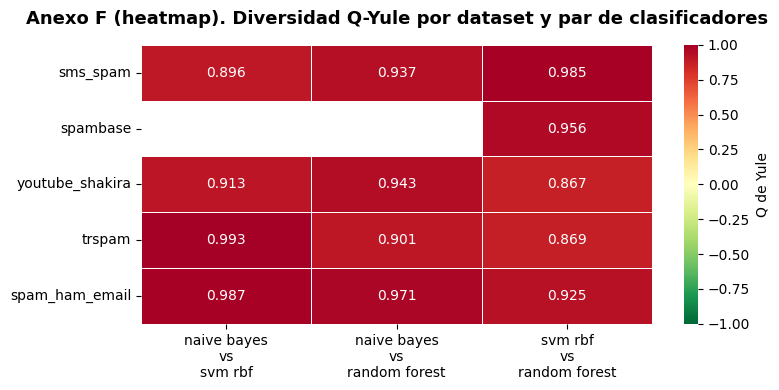

[OK] anexo_F_diversidad_heatmap.png


In [ ]:
# === GUARDAR TABLA Y FIGURA HEATMAP ===
save_table_png(
    df_div,
    title='Anexo F. Diversidad entre clasificadores base por dataset',
    subtitle='Q de Yule y porcentaje de desacuerdos sobre el conjunto de prueba',
    output_path=ANEXOS_DIR / 'anexo_F_diversidad.png',
    col_widths=[1.5, 2.2, 1.0, 1.0],
    fontsize=10,
)
df_div.to_csv(ANEXOS_DIR / 'anexo_F_diversidad.csv', index=False)

# Heatmap de Q por dataset
ds_list = list(hybrid_results.keys())
pairs_order = []
for ds in ds_list:
    div = hybrid_results[ds].get('diversity', {}).get('yule_q', {})
    for k in div.keys():
        if k not in pairs_order:
            pairs_order.append(k)

if pairs_order and ds_list:
    heat = np.full((len(ds_list), len(pairs_order)), np.nan)
    for i, ds in enumerate(ds_list):
        div = hybrid_results[ds].get('diversity', {}).get('yule_q', {})
        for j, k in enumerate(pairs_order):
            if k in div:
                heat[i, j] = div[k]

    fig, ax = plt.subplots(figsize=(max(8, len(pairs_order) * 2.5), max(4, len(ds_list) * 0.8)))
    sns.heatmap(heat, annot=True, fmt='.3f', cmap='RdYlGn_r',
                xticklabels=[p.replace('_vs_', '\nvs\n').replace('_', ' ') for p in pairs_order],
                yticklabels=ds_list, ax=ax, vmin=-1, vmax=1, center=0,
                cbar_kws={'label': 'Q de Yule'},
                linewidths=0.5, linecolor='white')
    ax.set_title('Anexo F (heatmap). Diversidad Q-Yule por dataset y par de clasificadores',
                 fontsize=13, fontweight='bold', pad=15)
    plt.tight_layout()
    plt.savefig(ANEXOS_DIR / 'anexo_F_diversidad_heatmap.png', dpi=200, bbox_inches='tight', facecolor='white')
    plt.show()
    print('[OK] anexo_F_diversidad_heatmap.png')

# Anexo G — Tiempos de entrenamiento por experimentoCosto computacional de cada combinación (dataset × representación × clasificador) entrenada con `GridSearchCV`. Permite a futuros investigadores anticipar el tiempo de cómputo y justifica el uso de cache de embeddings y la elección de hiperparámetros acotados.

In [ ]:
# === CARGAR Y PROCESAR TIEMPOS ===
df_times = df_clf[['dataset', 'representation', 'classifier', 'train_time_sec', 'test_f1_macro']].copy()
df_times = df_times.sort_values('train_time_sec', ascending=False).reset_index(drop=True)

# Tabla de top-25 mas costosos
top_n = min(25, len(df_times))
df_top_times = df_times.head(top_n).copy()
df_top_times.columns = ['Dataset', 'Representacion', 'Clasificador', 'Tiempo (s)', 'F1-macro Test']
df_top_times['Tiempo (s)'] = df_top_times['Tiempo (s)'].apply(lambda x: f'{x:.1f}')
df_top_times['F1-macro Test'] = df_top_times['F1-macro Test'].apply(lambda x: f'{x:.4f}')
df_top_times['Representacion'] = df_top_times['Representacion'].map(REPR_LABELS).fillna(df_top_times['Representacion'])
df_top_times['Clasificador'] = df_top_times['Clasificador'].map(CLF_LABELS).fillna(df_top_times['Clasificador'])

save_table_png(
    df_top_times,
    title=f'Anexo G.1. Top {top_n} experimentos por tiempo de entrenamiento',
    subtitle='Incluye GridSearchCV anidado (5-fold) y SMOTE cuando aplica',
    output_path=ANEXOS_DIR / 'anexo_G1_tiempos_top.png',
    col_widths=[1.4, 1.3, 1.2, 0.9, 1.0],
    fontsize=9,
)
df_times.to_csv(ANEXOS_DIR / 'anexo_G_tiempos_completo.csv', index=False)

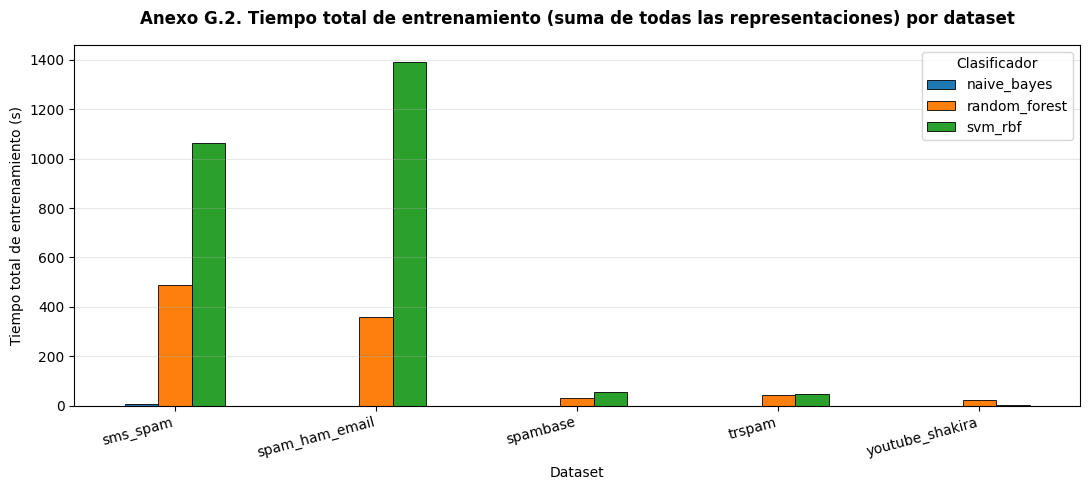

[OK] anexo_G2_tiempos_total.png

Tiempo total acumulado (entrenamiento + GridSearch): 3509.2s = 58.5 min = 0.97 h


In [ ]:
# === FIGURA: TIEMPO TOTAL POR DATASET Y CLASIFICADOR ===
pivot = df_times.pivot_table(index='dataset', columns='classifier',
                              values='train_time_sec', aggfunc='sum').fillna(0)

fig, ax = plt.subplots(figsize=(11, 5))
pivot.plot(kind='bar', ax=ax, edgecolor='black', linewidth=0.6,
           color=['#1f77b4', '#ff7f0e', '#2ca02c'])
ax.set_xlabel('Dataset')
ax.set_ylabel('Tiempo total de entrenamiento (s)')
ax.set_title('Anexo G.2. Tiempo total de entrenamiento (suma de todas las representaciones) por dataset',
             fontweight='bold', fontsize=12, pad=15)
ax.legend(title='Clasificador', loc='upper right')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig(ANEXOS_DIR / 'anexo_G2_tiempos_total.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print('[OK] anexo_G2_tiempos_total.png')

# Resumen
total_time = df_times['train_time_sec'].sum()
print(f'\nTiempo total acumulado (entrenamiento + GridSearch): {total_time:.1f}s '
      f'= {total_time/60:.1f} min = {total_time/3600:.2f} h')

# Anexo H — Comparativa F1-macro por representación vectorialEsta tabla justifica empíricamente la elección de la representación óptima reportada en el Anexo A: para cada par (dataset, clasificador) se muestran **todos** los F1-macro observados en validación cruzada y prueba a través de las distintas representaciones (BoW, TF-IDF, embeddings y sus variantes con reducción dimensional). Las celdas vacías indican combinaciones no compatibles (e.g. Naïve Bayes con embeddings densos).

In [ ]:
# === TABLA H: F1 POR (DATASET, CLF, REPR) ===
df_h = df_clf.pivot_table(
    index=['dataset', 'classifier'],
    columns='representation',
    values='test_f1_macro',
    aggfunc='max'
)

# Ordenar columnas en un orden semantico
preferred_order = ['bow', 'tfidf', 'emb', 'bow_svd', 'tfidf_svd', 'emb_pca', 'scaled', 'pca']
ordered_cols = [c for c in preferred_order if c in df_h.columns]
extras = [c for c in df_h.columns if c not in preferred_order]
df_h = df_h[ordered_cols + extras]

# Renombrar columnas
df_h.columns = [REPR_LABELS.get(c, c) for c in df_h.columns]
df_h = df_h.reset_index()
df_h['classifier'] = df_h['classifier'].map(CLF_LABELS).fillna(df_h['classifier'])
df_h.columns = ['Dataset', 'Clasificador'] + list(df_h.columns[2:])

# Formatear
def fmt(v):
    if pd.isna(v):
        return '-'
    return f'{v:.4f}'

for c in df_h.columns[2:]:
    df_h[c] = df_h[c].apply(fmt)

print(df_h.to_string(index=False))

        Dataset  Clasificador    BoW TF-IDF Embeddings BoW + SVD TF-IDF + SVD Embeddings + PCA StandardScaler StandardScaler + PCA
       sms_spam   Naive Bayes 0.9161 0.9191          -         -            -                -              -                    -
       sms_spam Random Forest 0.7976 0.9517     0.9333    0.9305       0.9307           0.9143              -                    -
       sms_spam     SVM (RBF) 0.7703 0.9306     0.9437    0.9399       0.9289           0.9335              -                    -
 spam_ham_email   Naive Bayes 0.9703 0.9566          -         -            -                -              -                    -
 spam_ham_email Random Forest 0.9570 0.9681     0.9295    0.9526       0.9737           0.9363              -                    -
 spam_ham_email     SVM (RBF) 0.9527 0.9808     0.9591    0.9516       0.9738           0.9565              -                    -
       spambase Random Forest      -      -          -         -            -      

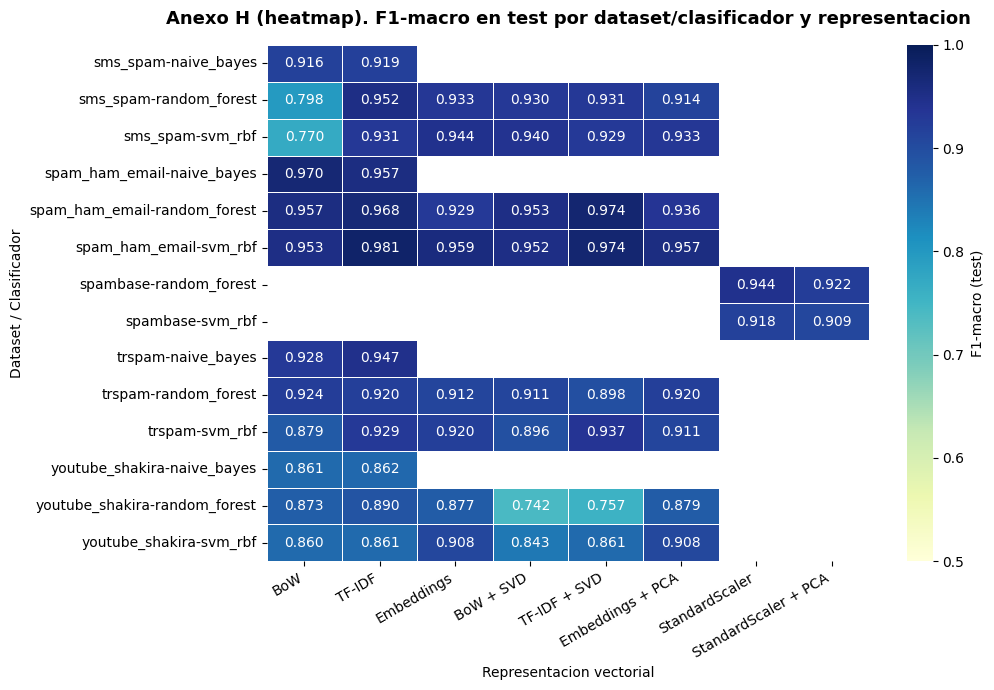

[OK] anexo_H_f1_por_representacion.png + anexo_H_f1_heatmap.png


In [ ]:
# === GUARDAR ANEXO H ===
n_cols_h = len(df_h.columns)
col_widths_h = [1.5, 1.2] + [0.8] * (n_cols_h - 2)

save_table_png(
    df_h,
    title='Anexo H. F1-macro en test por dataset, clasificador y representacion',
    subtitle='Celdas vacias = combinacion no compatible (e.g. Naive Bayes requiere features no negativas)',
    output_path=ANEXOS_DIR / 'anexo_H_f1_por_representacion.png',
    col_widths=col_widths_h,
    fontsize=9,
)
df_h.to_csv(ANEXOS_DIR / 'anexo_H_f1_por_representacion.csv', index=False)

# === HEATMAP COMPLEMENTARIO ===
df_h_num = df_clf.pivot_table(
    index=['dataset', 'classifier'],
    columns='representation',
    values='test_f1_macro',
    aggfunc='max'
)
df_h_num = df_h_num[ordered_cols + extras]
df_h_num.columns = [REPR_LABELS.get(c, c) for c in df_h_num.columns]

fig, ax = plt.subplots(figsize=(max(10, len(df_h_num.columns) * 1.3),
                                 max(4, len(df_h_num) * 0.5)))
sns.heatmap(df_h_num, annot=True, fmt='.3f', cmap='YlGnBu',
            ax=ax, cbar_kws={'label': 'F1-macro (test)'},
            linewidths=0.5, linecolor='white', vmin=0.5, vmax=1.0)
ax.set_title('Anexo H (heatmap). F1-macro en test por dataset/clasificador y representacion',
             fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Representacion vectorial')
ax.set_ylabel('Dataset / Clasificador')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(ANEXOS_DIR / 'anexo_H_f1_heatmap.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print('[OK] anexo_H_f1_por_representacion.png + anexo_H_f1_heatmap.png')

# Cierre — Resumen de archivos generadosListado consolidado de los archivos generados, listos para ser insertados en el documento de la tesis.

In [ ]:
# === RESUMEN FINAL ===
print('=' * 70)
print('ANEXOS GENERADOS')
print('=' * 70)
print(f'Carpeta: {ANEXOS_DIR}')
print()

archivos = sorted(ANEXOS_DIR.iterdir())
total_size = 0
for p in archivos:
    if p.is_file():
        kb = p.stat().st_size / 1024
        total_size += kb
        emoji = ' [PNG]' if p.suffix == '.png' else (' [CSV]' if p.suffix == '.csv' else (' [TXT]' if p.suffix == '.txt' else ' [JSON]'))
        print(f'  {emoji} {p.name:<50} ({kb:>7.1f} KB)')

print()
print(f'Total: {len(archivos)} archivos, {total_size/1024:.1f} MB')
print()
print('Listos para insertar en la tesis. Sugerencia de orden en el documento:')
print('  Anexo A: anexo_A_hiperparametros.png')
print('  Anexo B: anexo_B_preprocesamiento_EN.png + anexo_B_preprocesamiento_TR.png')
print('  Anexo C: anexo_C1_versiones.png + anexo_C2_configuracion.png +')
print('           anexo_C3_entorno.png + anexo_C4_hashes.png')
print('  Anexo D: anexo_D_top_tfidf_<dataset>.png  (uno por dataset textual)')
print('  Anexo E: anexo_E_longitudes_distribucion.png + anexo_E_longitudes_stats.png')
print('  Anexo F: anexo_F_diversidad.png + anexo_F_diversidad_heatmap.png')
print('  Anexo G: anexo_G1_tiempos_top.png + anexo_G2_tiempos_total.png')
print('  Anexo H: anexo_H_f1_por_representacion.png + anexo_H_f1_heatmap.png')
print()
print(f'Fecha: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')

ANEXOS GENERADOS
Carpeta: /content/drive/MyDrive/spam_tesis/results/figures/anexos

   [CSV] anexo_A_hiperparametros.csv                        (    1.1 KB)
   [PNG] anexo_A_hiperparametros.png                        (  284.3 KB)
   [PNG] anexo_B_preprocesamiento_EN.png                    (  386.9 KB)
   [TXT] anexo_B_preprocesamiento_EN.txt                    (    2.1 KB)
   [PNG] anexo_B_preprocesamiento_TR.png                    (  334.8 KB)
   [TXT] anexo_B_preprocesamiento_TR.txt                    (    3.2 KB)
   [PNG] anexo_C1_versiones.png                             (   98.9 KB)
   [PNG] anexo_C2_configuracion.png                         (  340.7 KB)
   [PNG] anexo_C3_entorno.png                               (   76.3 KB)
   [PNG] anexo_C4_hashes.png                                ( 1420.0 KB)
   [CSV] anexo_C4_hashes_completo.csv                       (   12.3 KB)
   [JSON] anexo_C_reproducibilidad.json                      (   12.8 KB)
   [CSV] anexo_D_top_tfidf_sms_spam.csv